# HMK / 01 — Markov transition matrices of MNQ: daily, 1 hour, 15 minutes (video rule, descriptive)

Protocol: [`HMK 002`](../../discussions/MNQ_Hierarchical_Markov/002_claude_hmk01_transition_matrices.md). Code: `src/equity_trading/hmk.py`. **No trading test.**

- **State of each bar** (the video's rule): sum of the last 20 bar log returns, this bar included: ≥ +5% bull, ≤ −5% bear, else sideways.
- **Tiers:** daily (CME day close-to-close), 1 hour and 15 minutes (session-aligned bars, all bars in time order across days).
- **Intraday bands:** the literal ±5% and the same band scaled to the bar length by √time (±1.04% for 1 h, ±0.52% for 15 m).
- **Per tier:** counts and the 3×3 matrix, its diagonal (persistence) and expected duration 1/(1 − p_ii), matrix powers (2, 3, 5, 20 bars), stationary distribution, run lengths, and — descriptive only — the share of next bars that close up by state.
- **Persistence references:** (A) the same returns shuffled, same rule (what 19 shared bars give by themselves); (B) states on non-overlapping 20-bar blocks.
- **Window:** 2020-01 – 2023-06, and its halves 2020-01 – 2021-09 / 2021-10 – 2023-06. 2023-07 onwards and 2026 untouched.

Environment: `HMK_SYNTHETIC=1` (random-walk smoke run), `HMK_SYNTH_DIR`.

In [1]:
import json, os, sys, tempfile, warnings
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
SYNTHETIC = os.environ.get("HMK_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("HMK_SYNTH_DIR") or tempfile.mkdtemp(prefix="hmk_")
    os.environ["HMK_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import hmk as H
from equity_trading import micro_bars as MB

D = dt.date
CFG = H.HMKConfig()
if SYNTHETIC:
    WINDOWS = {"all": (D(2020, 1, 1), D(2021, 6, 30)), "H1": (D(2020, 1, 1), D(2020, 9, 30)), "H2": (D(2020, 10, 1), D(2021, 6, 30))}
    if not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
        H.write_synthetic(os.environ["EQUITY_TRADING_DIR"], CFG.load_start, WINDOWS["all"][1], effect=0.0)
else:
    WINDOWS = {"all": (D(2020, 1, 1), D(2023, 6, 30)), "H1": (D(2020, 1, 1), D(2021, 9, 30)), "H2": (D(2021, 10, 1), D(2023, 6, 30))}
WINDOW_BARS, BAND = 20, 0.05
N_NULL = 50 if SYNTHETIC else 200
OUT = Path("01"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)
print("engine", H.HMK_VERSION, "| synthetic random walk" if SYNTHETIC else "| real data", "| windows", WINDOWS)

engine 0.1.0 | real data | windows {'all': (datetime.date(2020, 1, 1), datetime.date(2023, 6, 30)), 'H1': (datetime.date(2020, 1, 1), datetime.date(2021, 9, 30)), 'H2': (datetime.date(2021, 10, 1), datetime.date(2023, 6, 30))}


In [2]:
m1 = MB.load_1m(CFG.root, CFG.load_start, WINDOWS["all"][1] + dt.timedelta(days=1))
BARS = H.session_bars(m1, CFG)
del m1
# the 20-bar window needs history before the window starts: keep the run-in, report states from the window start
def series(tier, a, b):
    x = BARS[tier]
    t = pd.to_datetime(x.trade_date).dt.date
    return x[t <= b].reset_index(drop=True), (t[t <= b] >= a).to_numpy()
for tier, b in BARS.items():
    print(tier, "bars", len(b), "| first", b.trade_date.min(), "| last", b.trade_date.max(),
          "| median |ret| bp", round(float(np.nanmedian(np.abs(b.ret_bp))), 2))

1d bars 924 | first 2019-11-01 00:00:00 | last 2023-06-30 00:00:00 | median |ret| bp 90.88
1h bars 21252 | first 2019-11-01 00:00:00 | last 2023-06-30 00:00:00 | median |ret| bp 11.74
15m bars 85008 | first 2019-11-01 00:00:00 | last 2023-06-30 00:00:00 | median |ret| bp 5.46


In [3]:
def report(tier, band, win):
    x, inwin = series(tier, *WINDOWS[win])
    return H.chain_report(x.ret_bp.to_numpy(float), WINDOW_BARS, band, n_null=N_NULL, mask=inwin)

BANDS = {"1d": {"5%": BAND}, "1h": {"5%": BAND, "scaled": H.band_scaled("1h", BAND)},
         "15m": {"5%": BAND, "scaled": H.band_scaled("15m", BAND)}}
REP = {(t, bn, w): report(t, bv, w) for t, bands in BANDS.items() for bn, bv in bands.items() for w in WINDOWS}
SUM = []
for (t, bn, w), r in REP.items():
    for s in H.STATE_NAMES:
        SUM.append({"tier": t, "band": bn, "band_pct": 100 * r["band"], "window": w, "state": s, "n_bars": r["n_bars"],
                    "share": r["share"][s], "p_stay": r["diag"][s], "p_stay_shuffled": r["null_shuffle_diag_mean"][s],
                    "p_stay_shuffled_q95": r["null_shuffle_diag_q95"][s], "p_stay_nonoverlap": r["P_nonoverlap"].loc[s, s],
                    "expected_duration_bars": r["expected_duration"][s], "mean_run_bars": r["runs"].loc[s, "mean"],
                    "stationary": r["stationary"][s], "next_bar_up_share": r["next_bar_up_share"][s],
                    "next_bar_n": r["next_bar_n"][s]})
SUM = pd.DataFrame(SUM); SUM.to_csv(OUT / "01_summary.csv", index=False)
mats = []
for (t, bn, w), r in REP.items():
    for kind, M in (("P", r["P"]), ("counts", r["counts"]), ("P_nonoverlap", r["P_nonoverlap"])) + \
                   tuple((f"P^{n}", m) for n, m in r["P_steps"].items()):
        mats.append(M.reset_index(names="from").assign(tier=t, band=bn, window=w, matrix=kind))
pd.concat(mats).to_csv(OUT / "01_matrices.csv", index=False)
print("done", len(REP), "reports")

done 15 reports


## Daily

In [4]:
for bn in ('5%',):
    r = REP[("1d", bn, "all")]
    print(f"=== 1d | band {bn} = ±{100 * r['band']:.2f}% over 20 bars | bars {r['n_bars']} | non-overlapping blocks {r['n_blocks']}")
    print("state share:", r["share"].round(3).to_dict(), "| stationary:", r["stationary"].round(3).to_dict())
    print("counts"); display(r["counts"].astype(int))
    print("P(tomorrow | today)"); display(r["P"].round(3))
    print("persistence: diagonal vs shuffled-return null vs non-overlapping blocks")
    display(pd.DataFrame({"p_stay": r["diag"], "shuffled_mean": r["null_shuffle_diag_mean"], "shuffled_q95": r["null_shuffle_diag_q95"],
                          "non_overlapping": np.diag(r["P_nonoverlap"]), "expected_duration": r["expected_duration"]}).round(3))
    print("P^2, P^3, P^5, P^20"); display(pd.concat({f"P^{n}": m for n, m in r["P_steps"].items()}).round(3))
    print("runs (bars)"); display(r["runs"].round(2))
    print("halves: p_stay"); display(SUM[(SUM.tier == "1d") & (SUM.band == bn)].pivot_table(index="state", columns="window", values="p_stay").round(3))
    print("descriptive: share of next bars that close up, by state"); display(pd.DataFrame({"up_share": r["next_bar_up_share"], "n": r["next_bar_n"]}).round(4))

=== 1d | band 5% = ±5.00% over 20 bars | bars 882 | non-overlapping blocks 45
state share: {'bear': 0.175, 'side': 0.493, 'bull': 0.332} | stationary: {'bear': 0.176, 'side': 0.496, 'bull': 0.328}
counts


,bear,side,bull
bear,131,23,0
side,23,360,51
bull,0,52,241


P(tomorrow | today)


,bear,side,bull
bear,0.851,0.149,0.000
side,0.053,0.829,0.118
bull,0.000,0.177,0.823


persistence: diagonal vs shuffled-return null vs non-overlapping blocks


,p_stay,shuffled_mean,shuffled_q95,non_overlapping,expected_duration
bear,0.851,0.825,0.882,0.286,6.696
side,0.829,0.851,0.879,0.435,5.865
bull,0.823,0.866,0.902,0.214,5.635


... (4 outputs left out)

halves: p_stay


window,H1,H2,all
state,,,
bear,0.786,0.874,0.851
bull,0.795,0.861,0.823
side,0.815,0.847,0.829


descriptive: share of next bars that close up, by state


,up_share,n
bear,0.5232,151
side,0.5377,424
bull,0.5567,291


## 1 hour

In [5]:
for bn in ('5%', 'scaled'):
    r = REP[("1h", bn, "all")]
    print(f"=== 1h | band {bn} = ±{100 * r['band']:.2f}% over 20 bars | bars {r['n_bars']} | non-overlapping blocks {r['n_blocks']}")
    print("state share:", r["share"].round(3).to_dict(), "| stationary:", r["stationary"].round(3).to_dict())
    print("counts"); display(r["counts"].astype(int))
    print("P(tomorrow | today)"); display(r["P"].round(3))
    print("persistence: diagonal vs shuffled-return null vs non-overlapping blocks")
    display(pd.DataFrame({"p_stay": r["diag"], "shuffled_mean": r["null_shuffle_diag_mean"], "shuffled_q95": r["null_shuffle_diag_q95"],
                          "non_overlapping": np.diag(r["P_nonoverlap"]), "expected_duration": r["expected_duration"]}).round(3))
    print("P^2, P^3, P^5, P^20"); display(pd.concat({f"P^{n}": m for n, m in r["P_steps"].items()}).round(3))
    print("runs (bars)"); display(r["runs"].round(2))
    print("halves: p_stay"); display(SUM[(SUM.tier == "1h") & (SUM.band == bn)].pivot_table(index="state", columns="window", values="p_stay").round(3))
    print("descriptive: share of next bars that close up, by state"); display(pd.DataFrame({"up_share": r["next_bar_up_share"], "n": r["next_bar_n"]}).round(4))

=== 1h | band 5% = ±5.00% over 20 bars | bars 20286 | non-overlapping blocks 1015
state share: {'bear': 0.006, 'side': 0.989, 'bull': 0.004} | stationary: {'bear': 0.006, 'side': 0.989, 'bull': 0.004}
counts


,bear,side,bull
bear,107,24,0
side,24,20014,26
bull,0,26,64


P(tomorrow | today)


,bear,side,bull
bear,0.817,0.183,0.000
side,0.001,0.998,0.001
bull,0.000,0.289,0.711


persistence: diagonal vs shuffled-return null vs non-overlapping blocks


,p_stay,shuffled_mean,shuffled_q95,non_overlapping,expected_duration
bear,0.817,0.736,0.837,0.000,5.458
side,0.998,0.999,0.999,0.992,401.280
bull,0.711,0.806,0.889,0.000,3.462


... (18 outputs left out)

halves: p_stay


window,H1,H2,all
state,,,
bear,0.846,0.865,0.857
bull,0.841,0.853,0.847
side,0.912,0.882,0.899


descriptive: share of next bars that close up, by state


,up_share,n
bear,0.5120,3795
side,0.5291,11834
bull,0.5175,4412


## 15 minutes

In [6]:
for bn in ('5%', 'scaled'):
    r = REP[("15m", bn, "all")]
    print(f"=== 15m | band {bn} = ±{100 * r['band']:.2f}% over 20 bars | bars {r['n_bars']} | non-overlapping blocks {r['n_blocks']}")
    print("state share:", r["share"].round(3).to_dict(), "| stationary:", r["stationary"].round(3).to_dict())
    print("counts"); display(r["counts"].astype(int))
    print("P(tomorrow | today)"); display(r["P"].round(3))
    print("persistence: diagonal vs shuffled-return null vs non-overlapping blocks")
    display(pd.DataFrame({"p_stay": r["diag"], "shuffled_mean": r["null_shuffle_diag_mean"], "shuffled_q95": r["null_shuffle_diag_q95"],
                          "non_overlapping": np.diag(r["P_nonoverlap"]), "expected_duration": r["expected_duration"]}).round(3))
    print("P^2, P^3, P^5, P^20"); display(pd.concat({f"P^{n}": m for n, m in r["P_steps"].items()}).round(3))
    print("runs (bars)"); display(r["runs"].round(2))
    print("halves: p_stay"); display(SUM[(SUM.tier == "15m") & (SUM.band == bn)].pivot_table(index="state", columns="window", values="p_stay").round(3))
    print("descriptive: share of next bars that close up, by state"); display(pd.DataFrame({"up_share": r["next_bar_up_share"], "n": r["next_bar_n"]}).round(4))

=== 15m | band 5% = ±5.00% over 20 bars | bars 81144 | non-overlapping blocks 4058
state share: {'bear': 0.0, 'side': 0.999, 'bull': 0.001} | stationary: {'bear': 0.0, 'side': 0.999, 'bull': 0.001}
counts


,bear,side,bull
bear,26,11,0
side,11,81019,13
bull,0,13,50


P(tomorrow | today)


,bear,side,bull
bear,0.703,0.297,0.000
side,0.000,1.000,0.000
bull,0.000,0.206,0.794


persistence: diagonal vs shuffled-return null vs non-overlapping blocks


,p_stay,shuffled_mean,shuffled_q95,non_overlapping,expected_duration
bear,0.703,0.599,0.917,0.000,3.364
side,1.000,1.000,1.000,0.999,3376.792
bull,0.794,0.592,0.924,0.000,4.846


... (18 outputs left out)

halves: p_stay


window,H1,H2,all
state,,,
bear,0.848,0.847,0.847
bull,0.839,0.844,0.841
side,0.930,0.920,0.925


descriptive: share of next bars that close up, by state


,up_share,n
bear,0.5169,12373
side,0.5157,53300
bull,0.5141,13609


## Summary and heatmaps

expected_duration_bars  next_bar_up_share  p_stay  p_stay_nonoverlap  p_stay_shuffled  share
tier band   state                                                                                              
15m  5%     bear                    3.364              0.581   0.703              0.000            0.599  0.000
            bull                    4.846              0.466   0.794              0.000            0.592  0.001
            side                 3376.792              0.516   1.000              0.999            1.000  0.999
     scaled bear                    6.556              0.517   0.847              0.239            0.859  0.155
            bull                    6.294              0.514   0.841              0.215            0.861  0.171
            side                   13.413              0.516   0.925              0.718            0.884  0.674
1d   5%     bear                    6.696              0.523   0.851              0.286            0.825  0.175
            bull                    5.635              0.557   0.823              0.214            0.866  0.332
            side                    5.865              0.538   0.829              0.435            0.851  0.493
1h   5%     bear                    5.458              0.532   0.817              0.000            0.736  0.006
            bull                    3.462              0.500   0.711              0.000            0.806  0.004
            side                  401.280              0.523   0.998              0.992            0.999  0.989
     scaled bear                    6.991              0.512   0.857              0.246            0.856  0.189
            bull                    6.555              0.517   0.847              0.205            0.862  0.219
            side                    9.871              0.529   0.899              0.637            0.877  0.592

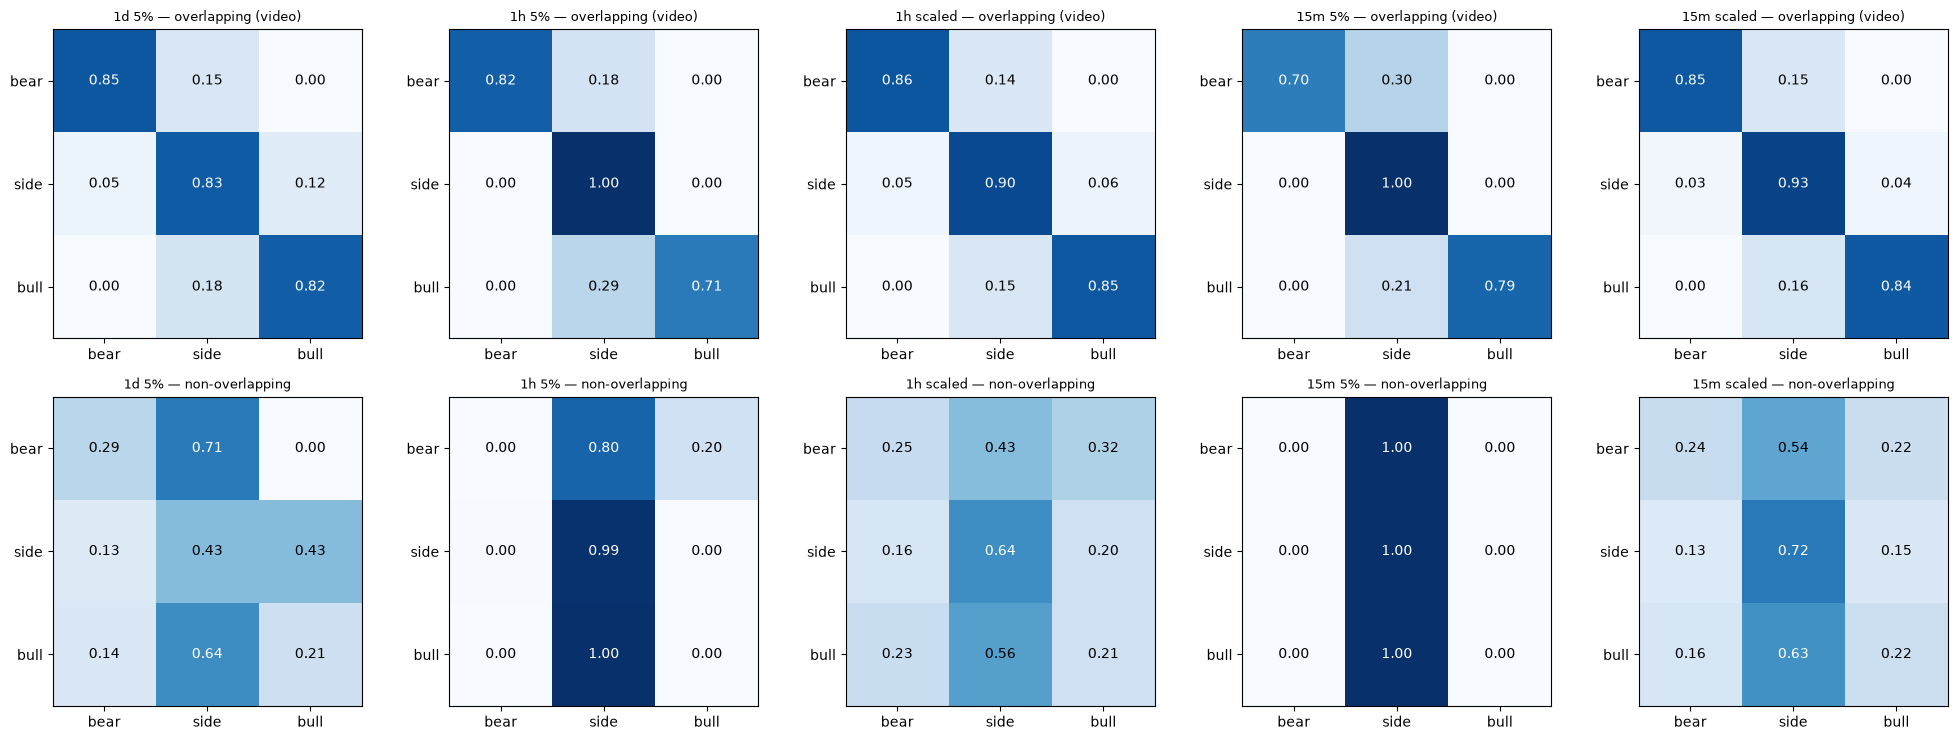

In [7]:
display(SUM[SUM.window == "all"].pivot_table(index=["tier", "band", "state"],
        values=["share", "p_stay", "p_stay_shuffled", "p_stay_nonoverlap", "expected_duration_bars", "next_bar_up_share"]).round(3))
keys = [k for k in REP if k[2] == "all"]
fig, ax = plt.subplots(2, len(keys), figsize=(4 * len(keys), 7.5))
for j, (t, bn, w) in enumerate(keys):
    for i, (kind, M) in enumerate((("overlapping (video)", REP[(t, bn, w)]["P"]), ("non-overlapping", REP[(t, bn, w)]["P_nonoverlap"]))):
        a = ax[i, j]; a.imshow(M.to_numpy(float), vmin=0, vmax=1, cmap="Blues")
        for (p, q), v in np.ndenumerate(M.to_numpy(float)):
            a.text(q, p, f"{v:.2f}" if np.isfinite(v) else "-", ha="center", va="center", color="k" if v < 0.6 else "w")
        a.set_xticks(range(3), H.STATE_NAMES); a.set_yticks(range(3), H.STATE_NAMES)
        a.set_title(f"{t} {bn} — {kind}", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "01_matrices.png", dpi=110); plt.show()
json.dump({"version": H.HMK_VERSION, "synthetic": SYNTHETIC, "windows": {k: [str(a), str(b)] for k, (a, b) in WINDOWS.items()},
           "window_bars": WINDOW_BARS, "bands": {t: b for t, b in BANDS.items()}, "n_null": N_NULL},
          open(OUT / "01_run.json", "w"), indent=1)